# Sara Aldsani Security and Risk Management practical workbook
**SRM_PCOM7E July 2026 — prepared 19 October 2026**

This notebook contains 12 newly prepared, runnable practice activities with sample data, checks and saved outputs. It is an illustrative unit sequence because the official detailed weekly exercise list was not supplied. It does not establish past posting, attendance, cloud deployment or a historical development diary.

The Unit 7–9 calculations reproduce and extend the supplied individual summary. All probability inputs are **analyst assumptions**, not observed company rates. The classification fixtures, loss assumptions and recovery traces are synthetic. Original group material is acknowledged in the references.

**Run:** use Python 3, install `matplotlib` for the two charts, then Run All from the top. All other code uses the standard library. No account, network request, Azure subscription or credentials are used. Exports are written under `sara_workbook_outputs` in the working directory. The companion `.py` file runs the same cells in order.


## Unit 1 Identify assets and consequences
**Task:** build an asset register and connect confidentiality, integrity and availability with business consequences. **Answer:** an asset list becomes useful when an owner and consequence are explicit (Joint Task Force Transformation Initiative, 2012).

In [1]:
from pathlib import Path
import math, json, csv, hashlib
OUT = Path("sara_workbook_outputs")
OUT.mkdir(exist_ok=True)
def show_saved_chart(path):
    try:
        from IPython import get_ipython
        from IPython.display import display, Image
    except ImportError:
        return
    if get_ipython() is not None:
        display(Image(filename=str(path)))
assets = [
    {"id":"A1", "asset":"Batch and recipe records", "owner":"Quality owner", "priority":"integrity", "consequence":"Incorrect product release"},
    {"id":"A2", "asset":"Customer delivery data", "owner":"Cathy", "priority":"confidentiality", "consequence":"Privacy harm"},
    {"id":"A3", "asset":"Ordering service", "owner":"Technology provider", "priority":"availability", "consequence":"Interrupted trading"}
]
assert len({a["id"] for a in assets}) == len(assets)
for a in assets:
    print(a["id"], a["asset"], "|", a["priority"], "|", a["consequence"])


A1 Batch and recipe records | integrity | Incorrect product release
A2 Customer delivery data | confidentiality | Privacy harm
A3 Ordering service | availability | Interrupted trading


## Unit 2 Construct a transparent qualitative register
**Task:** score selected Group 2 scenarios. **Answer:** thresholds below are newly chosen exercise rules. Ordinal products organise review and are not probabilities. The assessor requested explicit rating rules.

In [2]:
def band(score):
    if not 1 <= score <= 25:
        raise ValueError("Score must be 1..25")
    return "Critical" if score >= 20 else "High" if score >= 12 else "Medium" if score >= 6 else "Low"
risks = [
    {"id":"R1", "scenario":"Phishing diverts orders", "likelihood":4, "impact":4},
    {"id":"R4", "scenario":"Irrecoverable stock data loss", "likelihood":3, "impact":5},
    {"id":"R5", "scenario":"Unevidenced data accountability", "likelihood":3, "impact":3},
    {"id":"D1", "scenario":"Checkout tampering", "likelihood":4, "impact":5},
    {"id":"D5", "scenario":"Lost local supplier contingency", "likelihood":4, "impact":5}
]
for r in risks:
    assert 1 <= r["likelihood"] <= 5 and 1 <= r["impact"] <= 5
    r["score"] = r["likelihood"]*r["impact"]
    r["band"] = band(r["score"])
for r in sorted(risks, key=lambda x: (-x["score"], x["id"])):
    print(r["id"], r["score"], r["band"], r["scenario"])
assert band(5) == "Low" and band(6) == "Medium" and band(20) == "Critical"


D1 20 Critical Checkout tampering
D5 20 Critical Lost local supplier contingency
R1 16 High Phishing diverts orders
R4 15 High Irrecoverable stock data loss
R5 9 Medium Unevidenced data accountability


## Unit 3 Apply STRIDE to a specific information flow
**Task:** link threats to controls for an order and stock-update flow. **Answer:** a method structures threats; it does not certify coverage or address every product-safety hazard (Shevchenko et al., 2018).

In [3]:
stride = {
    "Spoofing": ("Stolen staff identity", "MFA and unique accounts"),
    "Tampering": ("Altered batch record", "Reviewed changes and integrity checks"),
    "Repudiation": ("Disputed stock adjustment", "Protected attributable audit events"),
    "Information disclosure": ("Leaked delivery address", "Least privilege and minimisation"),
    "Denial of service": ("Ordering unavailable", "Recovery plan and capacity checks"),
    "Elevation of privilege": ("Warehouse account gains admin access", "Role separation")
}
assert len(stride) == 6
for category, (threat, control) in stride.items():
    print(f"{category}: {threat} -> proposed control: {control}")


Spoofing: Stolen staff identity -> proposed control: MFA and unique accounts
Tampering: Altered batch record -> proposed control: Reviewed changes and integrity checks
Repudiation: Disputed stock adjustment -> proposed control: Protected attributable audit events
Information disclosure: Leaked delivery address -> proposed control: Least privilege and minimisation
Denial of service: Ordering unavailable -> proposed control: Recovery plan and capacity checks
Elevation of privilege: Warehouse account gains admin access -> proposed control: Role separation


## Unit 4 Calculate toy AND and OR attack-tree outcomes
**Task:** calculate combinations without adding overlapping event probabilities. **Answer:** complement multiplication requires independence; the inputs below are synthetic teaching values, unrelated to observed attacks.

In [4]:
def check_probabilities(ps):
    if any(not 0 <= p <= 1 for p in ps):
        raise ValueError("Every probability must lie in [0,1]")
def independent_or(ps):
    check_probabilities(ps)
    return 1-math.prod(1-p for p in ps)
def independent_and(ps):
    check_probabilities(ps)
    return math.prod(ps)
print("Independent OR, 0.10 and 0.20:", round(independent_or([.10,.20]), 4))
print("Independent AND, 0.10 and 0.20:", round(independent_and([.10,.20]), 4))
assert math.isclose(independent_or([.10,.20]), .28)
assert math.isclose(independent_and([.10,.20]), .02)
try:
    independent_or([1.1])
except ValueError as error:
    print("Invalid input rejected:", error)


Independent OR, 0.10 and 0.20: 0.28
Independent AND, 0.10 and 0.20: 0.02
Invalid input rejected: Every probability must lie in [0,1]


## Unit 5 Evaluate a simple loss scenario
**Task:** compute single-loss and annualised-loss estimates. **Answer:** these illustrative monetary assumptions do not establish Pampered Pets' actual costs or justify accepting a safety risk.

In [5]:
asset_value = 20000  # assumed currency units, not a company valuation
exposure_factor = .25
annual_event_rate = .4  # expected events per year, not probability of any annual event
single_loss = asset_value*exposure_factor
annual_loss = single_loss*annual_event_rate
control_annual_cost = 900
assumed_remaining_loss_fraction = .4
avoided_loss = annual_loss*(1-assumed_remaining_loss_fraction)
net_annual_benefit = avoided_loss-control_annual_cost
print("Single loss:", single_loss, "currency units")
print("Annualised loss:", annual_loss, "currency units/year")
print("Avoided loss under assumed control effect:", avoided_loss)
print("Net annual benefit under assumptions:", net_annual_benefit)
assert single_loss == 5000 and annual_loss == 2000 and net_annual_benefit == 300


Single loss: 5000.0 currency units
Annualised loss: 2000.0 currency units/year
Avoided loss under assumed control effect: 1200.0
Net annual benefit under assumptions: 300.0


## Unit 6 Connect a treatment to its owner and evidence
**Task:** extend an entry with implementation responsibility and a provisional residual judgement. **Answer:** scenario scores are not measured control benefits. This responds to the Group 2 feedback.

In [6]:
treatment = {
    "risk_id":"R1", "owner":"Cathy", "action":"Verify MFA and payment-change callbacks",
    "deadline":"Before pilot launch", "estimated_annual_cost":900,
    "verification":"Configuration review and authorised callback exercise",
    "residual_likelihood_assumption":2, "residual_impact_assumption":4,
    "status":"PROPOSED; not implemented or verified"
}
original = next(r for r in risks if r["id"] == treatment["risk_id"])
residual_score = treatment["residual_likelihood_assumption"]*treatment["residual_impact_assumption"]
print(json.dumps(treatment, indent=2))
print("Original score:", original["score"], "Proposed residual:", residual_score, band(residual_score))
assert residual_score == 8 and treatment["status"].startswith("PROPOSED")


{
  "risk_id": "R1",
  "owner": "Cathy",
  "action": "Verify MFA and payment-change callbacks",
  "deadline": "Before pilot launch",
  "estimated_annual_cost": 900,
  "verification": "Configuration review and authorised callback exercise",
  "residual_likelihood_assumption": 2,
  "residual_impact_assumption": 4,
  "status": "PROPOSED; not implemented or verified"
}
Original score: 16 Proposed residual: 8 Medium


## Unit 7 Reproduce the quality event tree and classify sample defects
**Task:** distinguish defect initiation from escape through controls. **Answer:** sum disjoint primary branches, retaining all defect flags for review. The priority rule below is an example procedure; it needs quality-owner approval and does not establish real-world exclusivity (Sara, 2026b).

In [7]:
quality_initiation = [.025,.018,.012]
quality_escape = [.12,.15,.25]
quality_escape_target = [.04,.05,.08]
def quality_probability(initiation, escape):
    if len(initiation) != len(escape):
        raise ValueError("Branch lengths differ")
    check_probabilities(initiation+escape)
    if sum(initiation) > 1:
        raise ValueError("Disjoint initiation probabilities exceed one")
    return sum(a*b for a,b in zip(initiation,escape))
quality_baseline = quality_probability(quality_initiation, quality_escape)
quality_target = quality_probability(quality_initiation, quality_escape_target)
containment = sum(quality_initiation)-quality_baseline
priority = ["supplier", "packaging", "record"]
sample_batches = [
    {"id":"B1", "flags":["record","supplier"]},
    {"id":"B2", "flags":["packaging"]},
    {"id":"B3", "flags":[]}
]
for batch in sample_batches:
    assert set(batch["flags"]) <= set(priority)
    batch["primary"] = next((p for p in priority if p in batch["flags"]), "none")
    batch["requires_review"] = len(batch["flags"]) > 1
    print(batch)
print(f"Quality baseline: {quality_baseline:.4%}; target: {quality_target:.4%}; contained: {containment:.4%}")
assert math.isclose(quality_baseline,.0087) and math.isclose(quality_target,.00286)
assert math.isclose(containment,.0463) and sample_batches[0]["requires_review"]


{'id': 'B1', 'flags': ['record', 'supplier'], 'primary': 'supplier', 'requires_review': True}
{'id': 'B2', 'flags': ['packaging'], 'primary': 'packaging', 'requires_review': False}
{'id': 'B3', 'flags': [], 'primary': 'none', 'requires_review': False}
Quality baseline: 0.8700%; target: 0.2860%; contained: 4.6300%


## Unit 8 Reproduce delivery dependence and probability bounds
**Task:** separate a shared systems incident from residual delivery mechanisms. **Answer:** multiply initiation and fallback-failure probabilities, then use an OR calculation conditional on no shared incident (Sara, 2026b).

In [8]:
delivery_initiation = [.10,.07,.05,.04,.03]
fallback_failure = [.30,.25,.20,.40,.20]
residual = [a*b for a,b in zip(delivery_initiation,fallback_failure)]
def delivery_probability(shared, branches):
    check_probabilities([shared]+branches)
    return shared+(1-shared)*independent_or(branches)
shared = .02
late_baseline = delivery_probability(shared,residual)
late_target = delivery_probability(.005,[p/2 for p in residual])
lower_bound = shared+(1-shared)*max(residual)
upper_bound = shared+(1-shared)*min(1,sum(residual))
print("Conditional residual branches:", residual)
print(f"Late shipment baseline: {late_baseline:.4%}; target: {late_target:.4%}")
print(f"Dependence bounds: {lower_bound:.4%} to {upper_bound:.4%}")
print(f"Shared incident at 6%: {delivery_probability(.06,residual):.4%}")
assert math.isclose(late_baseline,.0956281280000002,abs_tol=1e-9)
assert lower_bound <= late_baseline <= upper_bound


Conditional residual branches: [0.03, 0.0175, 0.010000000000000002, 0.016, 0.006]
Late shipment baseline: 9.5628%; target: 4.3968%
Dependence bounds: 4.9400% to 9.7910%
Shared incident at 6%: 13.2541%


## Unit 9 Test uncertainty in individual quality inputs
**Task:** vary one initiation or escape input at a time by ±20%. **Answer:** these chosen ranges address the feedback's input-uncertainty question but are sensitivity scenarios, not confidence intervals or elicited expert ranges.

Supplier initiation: 0.8100% to 0.9300%
Packaging initiation: 0.8160% to 0.9240%
Record initiation: 0.8100% to 0.9300%
Supplier escape: 0.8100% to 0.9300%
Packaging escape: 0.8160% to 0.9240%
Record escape: 0.8100% to 0.9300%
Saved sara_workbook_outputs/quality_sensitivity.png


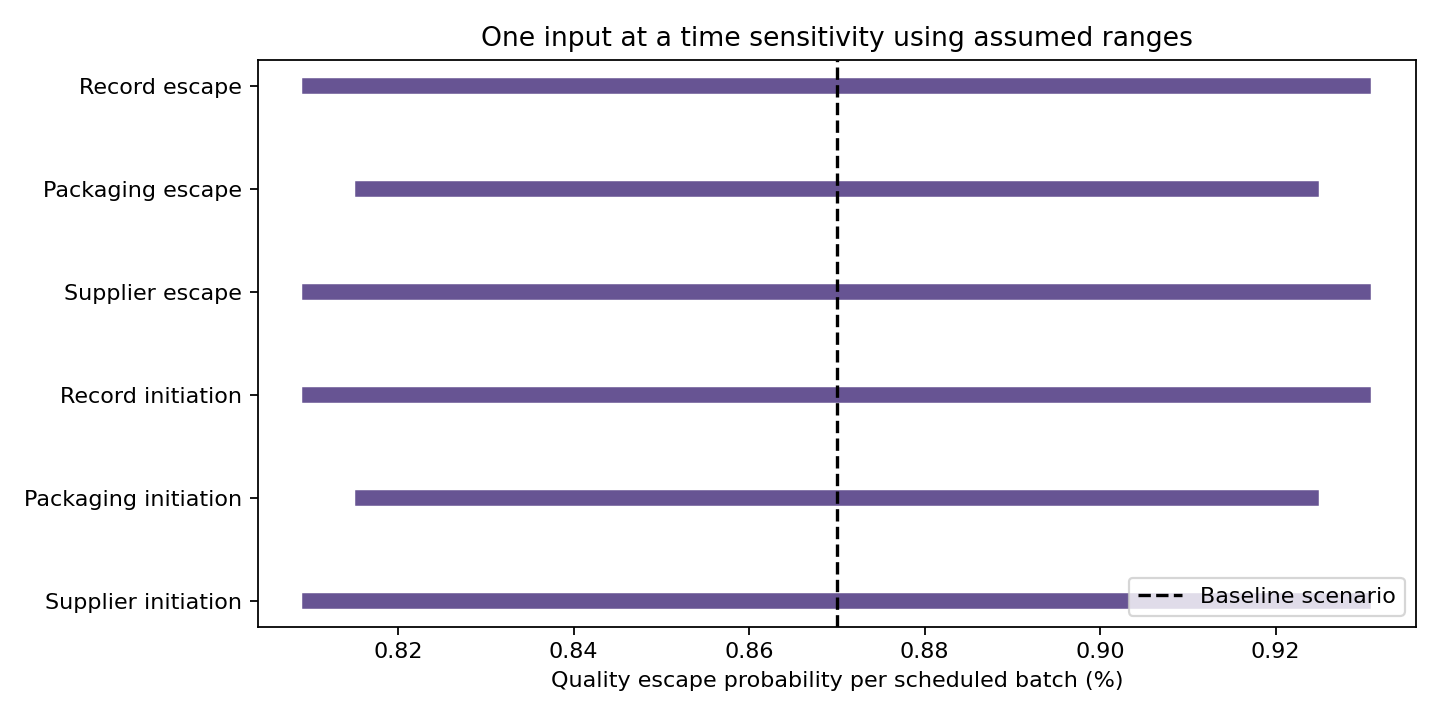

In [9]:
sensitivity = []
labels = ["Supplier initiation","Packaging initiation","Record initiation",
          "Supplier escape","Packaging escape","Record escape"]
for index,label in enumerate(labels):
    values=[]
    for factor in [.8,1.2]:
        initiation=quality_initiation.copy(); escape=quality_escape.copy()
        if index < 3:
            initiation[index] *= factor
        else:
            escape[index-3] *= factor
        values.append(quality_probability(initiation,escape))
    sensitivity.append({"input":label,"low":values[0],"high":values[1]})
for row in sensitivity:
    print(f"{row['input']}: {row['low']:.4%} to {row['high']:.4%}")
assert all(r["low"] < quality_baseline < r["high"] for r in sensitivity)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4.5))
for i,row in enumerate(sensitivity):
    ax.plot([row["low"]*100,row["high"]*100],[i,i],linewidth=7,color="#675493")
ax.axvline(quality_baseline*100,color="black",linestyle="--",label="Baseline scenario")
ax.set_yticks(range(len(labels)),labels)
ax.set_xlabel("Quality escape probability per scheduled batch (%)")
ax.set_title("One input at a time sensitivity using assumed ranges")
ax.legend(loc="lower right");fig.tight_layout()
fig.savefig(OUT/"quality_sensitivity.png",dpi=160);plt.close(fig)
print("Saved", OUT/"quality_sensitivity.png")
show_saved_chart(OUT/"quality_sensitivity.png")


## Unit 10 Evaluate simulated RTO and RPO evidence
**Task:** check a target trace and failure examples. **Answer:** the required interruption is strictly below 60 seconds; data loss is at most 60 seconds. These synthetic checks do not test Azure, SQL Server, quorum or actual durability.

SIMULATED {'name': 'Target example', 'rto': 50, 'rpo': 0, 'pass': True}
SIMULATED {'name': 'Slow recovery example', 'rto': 67, 'rpo': 0, 'pass': False}
SIMULATED {'name': 'Excess data loss example', 'rto': 45, 'rpo': 75, 'pass': False}
SIMULATED {'name': 'RTO boundary example', 'rto': 60, 'rpo': 60, 'pass': False}


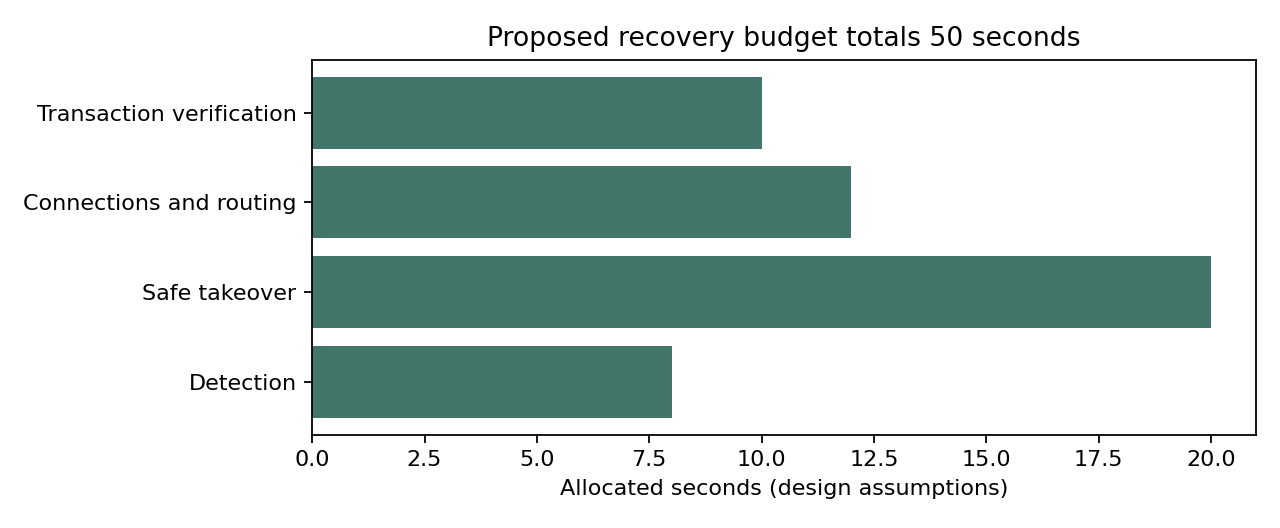

In [10]:
budget = {"Detection":8,"Safe takeover":20,"Connections and routing":12,"Transaction verification":10}
assert sum(budget.values()) == 50
simulated_traces = [
    {"name":"Target example", "rto":50,"rpo":0},
    {"name":"Slow recovery example", "rto":67,"rpo":0},
    {"name":"Excess data loss example", "rto":45,"rpo":75},
    {"name":"RTO boundary example", "rto":60,"rpo":60}
]
for trace in simulated_traces:
    trace["pass"] = trace["rto"] < 60 and trace["rpo"] <= 60
    print("SIMULATED",trace)
assert [t["pass"] for t in simulated_traces] == [True,False,False,False]
fig,ax=plt.subplots(figsize=(8,3.3));ax.barh(list(budget),list(budget.values()),color="#42766a")
ax.set_xlabel("Allocated seconds (design assumptions)");ax.set_title("Proposed recovery budget totals 50 seconds")
fig.tight_layout();fig.savefig(OUT/"recovery_budget.png",dpi=160);plt.close(fig)
show_saved_chart(OUT/"recovery_budget.png")


## Unit 11 Produce a compact results and assurance register
**Task:** export results with units and provenance. **Answer:** verification of arithmetic is separate from calibration of inputs and verification of the Azure design.

In [11]:
results = [
    {"metric":"Quality baseline","probability":quality_baseline,"unit":"per scheduled batch","provenance":"Supplied analyst assumptions"},
    {"metric":"Quality target","probability":quality_target,"unit":"per scheduled batch","provenance":"Proposed escape rates; not tested"},
    {"metric":"Late shipment baseline","probability":late_baseline,"unit":"per planned shipment","provenance":"Supplied analyst assumptions"},
    {"metric":"Late shipment target","probability":late_target,"unit":"per planned shipment","provenance":"Proposed residual changes; not tested"}
]
for result in results:
    print(result["metric"], f"{result['probability']:.4%}",result["unit"],"|",result["provenance"])
assurance = {
    "exclusive_quality_categories":"Example classification only; approval required",
    "input_calibration":"No observed incident or inspection dataset supplied",
    "Azure_quorum_and_commit_settings":"Requires explicit configuration and technical testing",
    "recovery_target":"Simulated examples only; no observed failover",
    "regulatory_and_standards_conformity":"Not established by this workbook"
}
print(json.dumps(assurance,indent=2))


Quality baseline 0.8700% per scheduled batch | Supplied analyst assumptions
Quality target 0.2860% per scheduled batch | Proposed escape rates; not tested
Late shipment baseline 9.5628% per planned shipment | Supplied analyst assumptions
Late shipment target 4.3968% per planned shipment | Proposed residual changes; not tested
{
  "exclusive_quality_categories": "Example classification only; approval required",
  "input_calibration": "No observed incident or inspection dataset supplied",
  "Azure_quorum_and_commit_settings": "Requires explicit configuration and technical testing",
  "recovery_target": "Simulated examples only; no observed failover",
  "regulatory_and_standards_conformity": "Not established by this workbook"
}


## Unit 12 Export reproducible artefacts and check their contents
**Task:** write CSV and JSON evidence files, then verify a read-back. **Answer:** exported material documents the new exercise run. It is not a substitute for original weekly artefacts or a cloud execution log.

In [12]:
with (OUT/"risk_register.csv").open("w",newline="",encoding="utf-8") as stream:
    writer=csv.DictWriter(stream,fieldnames=list(risks[0]));writer.writeheader();writer.writerows(risks)
with (OUT/"model_results.csv").open("w",newline="",encoding="utf-8") as stream:
    writer=csv.DictWriter(stream,fieldnames=list(results[0]));writer.writeheader();writer.writerows(results)
payload={"results":results,"sensitivity":sensitivity,"simulated_recovery":simulated_traces,"assurance":assurance}
(OUT/"workbook_results.json").write_text(json.dumps(payload,indent=2),encoding="utf-8")
loaded=json.loads((OUT/"workbook_results.json").read_text())
assert len(loaded["results"]) == 4 and len(loaded["simulated_recovery"]) == 4
for path in sorted(OUT.iterdir()):
    if path.is_file():
        print(path.name, "bytes=",path.stat().st_size,"sha256=",hashlib.sha256(path.read_bytes()).hexdigest()[:16])
print("All exercise assertions passed. Outputs describe new local exercises only.")


model_results.csv bytes= 384 sha256= ad969bbf4dee6bd3
quality_sensitivity.png bytes= 61125 sha256= 3882190909793cd9
recovery_budget.png bytes= 41569 sha256= b6618cfb29e5f876
risk_register.csv bytes= 268 sha256= 8382eb7227089bd5
workbook_results.json bytes= 2189 sha256= e1cf33d7db229bd2
All exercise assertions passed. Outputs describe new local exercises only.


## Harvard references and attribution
Group 2 (2026) *Pampered Pets risk identification report*. SRM_PCOM7E July 2026. Supplied student group report.

Sara (2026a) *Updated peer evaluation Group 2*. Supplied student document. The name field in the source is blank; attribution follows the user's identification of Sara Aldsani.

Sara (2026b) *Pampered Pets international expansion risk and recovery appraisal*. Individual Project Executive Summary. Supplied student document.

Joint Task Force Transformation Initiative (2012) *Guide for conducting risk assessments*. NIST SP 800-30 Rev. 1. doi:10.6028/NIST.SP.800-30r1.

Shevchenko, N., Chick, T.A., O’Riordan, P., Scanlon, T.P. and Woody, C. (2018) *Threat modeling A summary of available methods*. Carnegie Mellon University Software Engineering Institute. Available at: https://www.sei.cmu.edu/library/threat-modeling-a-summary-of-available-methods/ (Accessed: 19 October 2026).

Microsoft (no date) *Always On availability group on SQL Server on Azure VMs*. Available at: https://learn.microsoft.com/en-us/azure/azure-sql/virtual-machines/windows/availability-group-overview (Accessed: 19 October 2026).

The Python code, sample classification rule, charts and simulated traces are newly prepared learning examples. No historical authorship, implementation or measurement is claimed. Acknowledge assistance according to the module's AI guidance.
